In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os

zip_path = "/content/drive/MyDrive/archive.zip"

if os.path.exists(zip_path):
    print("ZIP file found!")
    print("File size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
else:
    print("ZIP file not found. Check its location in Google Drive.")

ZIP file found!
File size: 185.45 MB


In [5]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/ship_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: /content/ship_dataset


In [6]:
import os

dataset_path = "/content/ship_dataset"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 2:
        print(f"\nFolder: {root}")

        for filename in files[:10]:
            print("  ", filename)

        if level >= 2:
            dirs[:] = []


Folder: /content/ship_dataset
   shipsnet.json

Folder: /content/ship_dataset/shipsnet

Folder: /content/ship_dataset/shipsnet/shipsnet
   1__20170618_180801_0f34__-122.33155929465931_37.74030283783155.png
   0__20170504_180617_102d__-122.38874792550897_37.804101699435726.png
   1__20170515_180653_1007__-122.34143845365242_37.75128237373034.png
   1__20170419_181315_0e0d__-122.33515203635797_37.73072415039726.png
   1__20180705_182236_0f4d__-122.34239097094304_37.75139584987269.png
   1__20180312_182016_1042__-122.33270117893291_37.71929963254146.png
   1__20161102_202001_0c75__-122.34142381191572_37.74909210060885.png
   1__20170909_181730_0e0f__-122.34108889370289_37.7177244382296.png
   0__20161218_180845_0e26__-122.33170129781017_37.785080771313474.png
   0__20170414_180529_0f28__-122.28908216579555_37.73859416929502.png

Folder: /content/ship_dataset/scenes

Folder: /content/ship_dataset/scenes/scenes
   lb_4.png
   sfbay_3.png
   lb_1.png
   sfbay_2.png
   sfbay_4.png
   sfbay_1

In [7]:
import os

dataset_path = "/content/ship_dataset"

print("Checking dataset files...\n")

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level <= 3:
        print(f"\nFolder: {root}")

        for filename in files[:8]:
            print("  ", filename)

Checking dataset files...


Folder: /content/ship_dataset
   shipsnet.json

Folder: /content/ship_dataset/shipsnet

Folder: /content/ship_dataset/shipsnet/shipsnet
   1__20170618_180801_0f34__-122.33155929465931_37.74030283783155.png
   0__20170504_180617_102d__-122.38874792550897_37.804101699435726.png
   1__20170515_180653_1007__-122.34143845365242_37.75128237373034.png
   1__20170419_181315_0e0d__-122.33515203635797_37.73072415039726.png
   1__20180705_182236_0f4d__-122.34239097094304_37.75139584987269.png
   1__20180312_182016_1042__-122.33270117893291_37.71929963254146.png
   1__20161102_202001_0c75__-122.34142381191572_37.74909210060885.png
   1__20170909_181730_0e0f__-122.34108889370289_37.7177244382296.png

Folder: /content/ship_dataset/scenes

Folder: /content/ship_dataset/scenes/scenes
   lb_4.png
   sfbay_3.png
   lb_1.png
   sfbay_2.png
   sfbay_4.png
   sfbay_1.png
   lb_3.png
   lb_2.png


In [8]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Dataset paths
DATASET_PATH = "/content/ship_dataset"
JSON_PATH = os.path.join(DATASET_PATH, "shipsnet.json")

# Load JSON dataset
with open(JSON_PATH, "r") as f:
    data = json.load(f)

print("Dataset loaded successfully!")
print("Available keys:", data.keys())

Dataset loaded successfully!
Available keys: dict_keys(['data', 'labels', 'locations', 'scene_ids'])


In [9]:
images = np.array(data["data"])
labels = np.array(data["labels"])

print("Total images:", len(images))
print("Total labels:", len(labels))
print("Image data shape:", images.shape)
print("Label shape:", labels.shape)

unique_labels, counts = np.unique(labels, return_counts=True)

print("\nClass distribution:")
for label, count in zip(unique_labels, counts):
    class_name = "Ship" if label == 1 else "No-ship"
    print(f"{class_name}: {count}")

Total images: 4000
Total labels: 4000
Image data shape: (4000, 19200)
Label shape: (4000,)

Class distribution:
No-ship: 3000
Ship: 1000


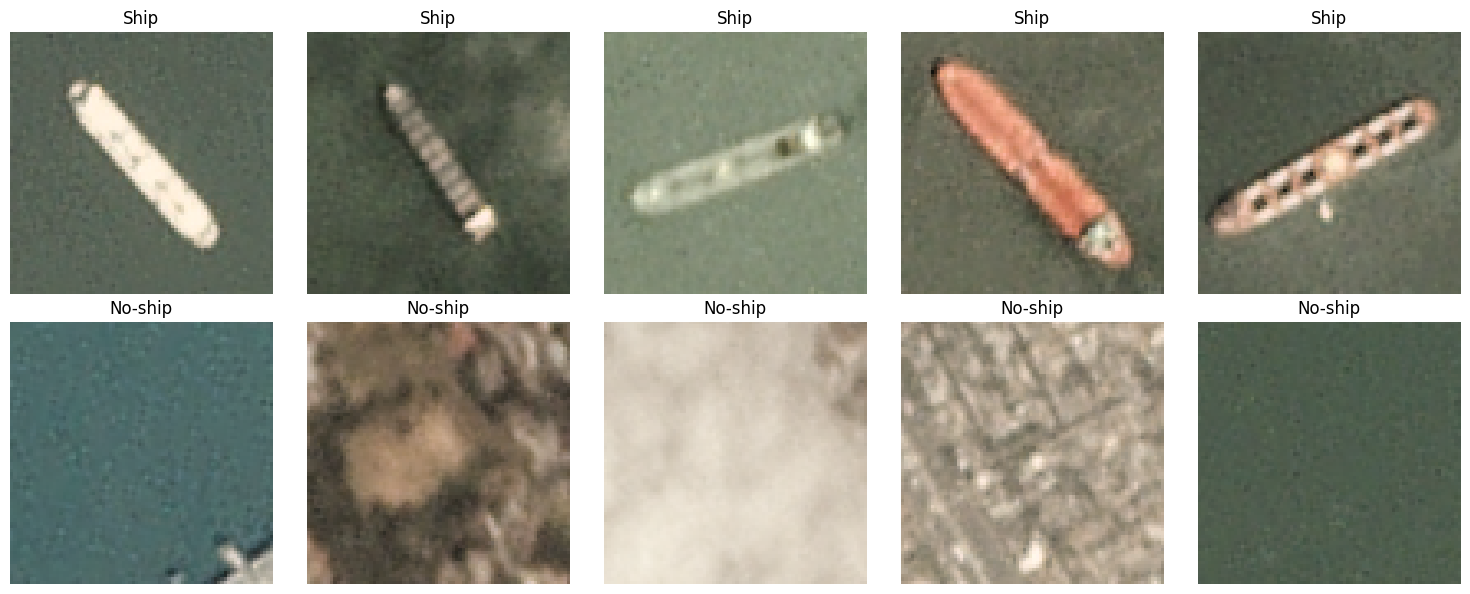

In [10]:
# Display sample images from both classes
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for row, label in enumerate([1, 0]):
    indices = np.where(labels == label)[0][:5]

    for col, idx in enumerate(indices):
        # Each image contains 80 x 80 x 3 pixel values
        image = images[idx].reshape(3, 80, 80).transpose(1, 2, 0)

        axes[row, col].imshow(image.astype(np.uint8))
        axes[row, col].set_title(
            "Ship" if label == 1 else "No-ship"
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

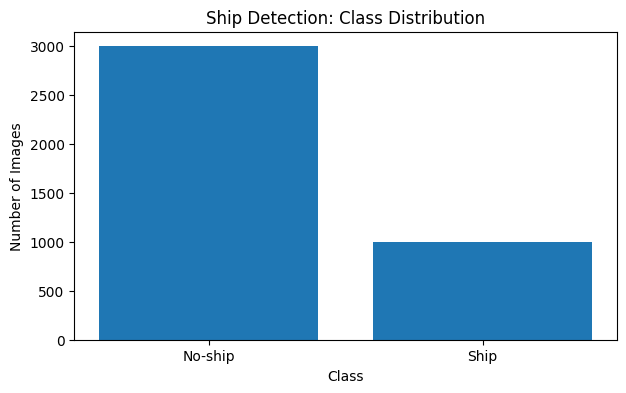

Ship-to-No-ship ratio: 0.333


In [11]:
class_names = {
    0: "No-ship",
    1: "Ship"
}

class_counts = pd.Series(labels).value_counts().sort_index()

plt.figure(figsize=(7, 4))
plt.bar(
    [class_names[int(i)] for i in class_counts.index],
    class_counts.values
)
plt.title("Ship Detection: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

print("Ship-to-No-ship ratio:",
      round(class_counts.get(1, 0) / class_counts.get(0, 1), 3))

In [12]:
import numpy as np

# Convert flattened image data into 80 x 80 RGB images
X = images.reshape(-1, 3, 80, 80).transpose(0, 2, 3, 1)

# Normalize pixel values to the range [0, 1]
X = X.astype("float32") / 255.0

# Convert labels to integers
y = labels.astype("int32")

print("Image tensor shape:", X.shape)
print("Label tensor shape:", y.shape)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Image tensor shape: (4000, 80, 80, 3)
Label tensor shape: (4000,)
Minimum pixel value: 0.003921569
Maximum pixel value: 1.0


In [13]:
from sklearn.model_selection import train_test_split

# First, separate the training set from the remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split the remaining data equally into validation and test sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTraining class counts:")
print("No-ship:", np.sum(y_train == 0))
print("Ship:", np.sum(y_train == 1))

print("\nValidation class counts:")
print("No-ship:", np.sum(y_val == 0))
print("Ship:", np.sum(y_val == 1))

print("\nTest class counts:")
print("No-ship:", np.sum(y_test == 0))
print("Ship:", np.sum(y_test == 1))

Training images: 2800
Validation images: 600
Testing images: 600

Training class counts:
No-ship: 2100
Ship: 700

Validation class counts:
No-ship: 450
Ship: 150

Test class counts:
No-ship: 450
Ship: 150


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Set reproducible random seeds
tf.keras.utils.set_random_seed(42)

# Build CNN architecture
model = models.Sequential([
    layers.Input(shape=(80, 80, 3)),

    # Data augmentation for training
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.25),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 80, 80, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 80, 80, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 80, 80, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class weights:", class_weights)

Class weights: {0: 0.6666666666666666, 1: 2.0}


In [16]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Stop if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

# Save the best model
checkpoint = ModelCheckpoint(
    "/content/best_ship_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Train the CNN
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    class_weight=class_weights,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/20
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6422 - loss: 0.6848
Epoch 1: val_loss improved from None to 0.68345, saving model to /content/best_ship_model.keras

Epoch 1: finished saving model to /content/best_ship_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.6871 - loss: 0.6941 - val_accuracy: 0.7150 - val_loss: 0.6834
Epoch 2/20
85/88 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6953 - loss: 0.6769
Epoch 2: val_loss improved from 0.68345 to 0.55908, saving model to /content/best_ship_model.keras

Epoch 2: finished saving model to /content/best_ship_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.6671 - loss: 0.6784 - val_accuracy: 0.7417 - val_loss: 0.5591
Epoch 3/20
85/88 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6416 - loss: 0.6095
Epoch 3: val_loss improved from 0.55908 to 0.47247, saving model to /content/best_ship_model.keras

Epoch 3: finished saving model to /content/best_ship_model.keras
88/88 ━━━━━━━━━━━━━━━

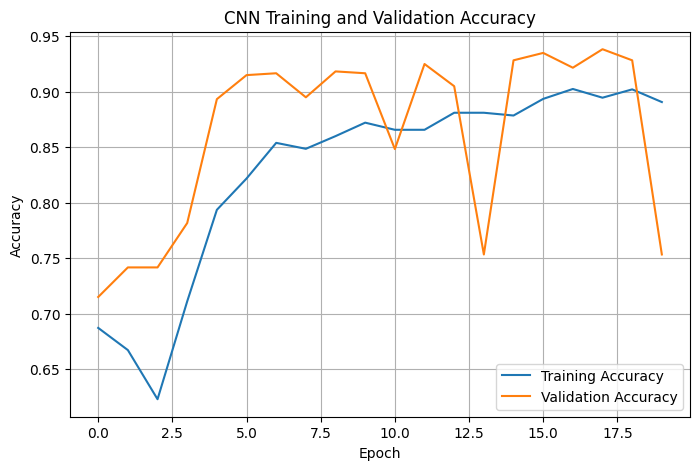

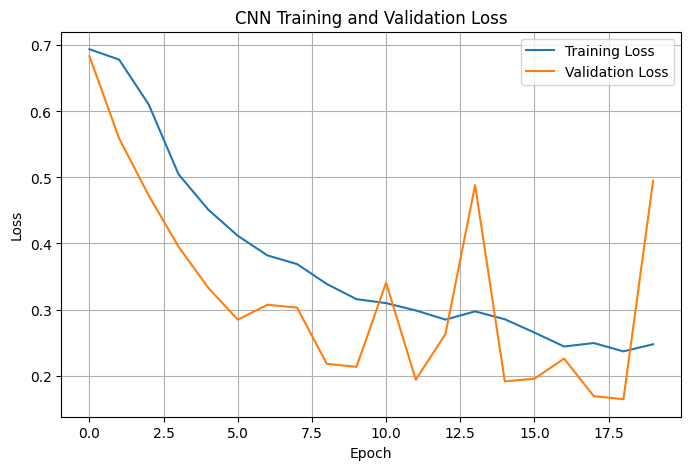

In [17]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
Test Accuracy: 0.9083

Classification Report:

              precision    recall  f1-score   support

     No-ship     0.9399    0.9378    0.9388       450
        Ship     0.8146    0.8200    0.8173       150

    accuracy                         0.9083       600
   macro avg     0.8772    0.8789    0.8780       600
weighted avg     0.9085    0.9083    0.9084       600

Macro F1-score: 0.8780


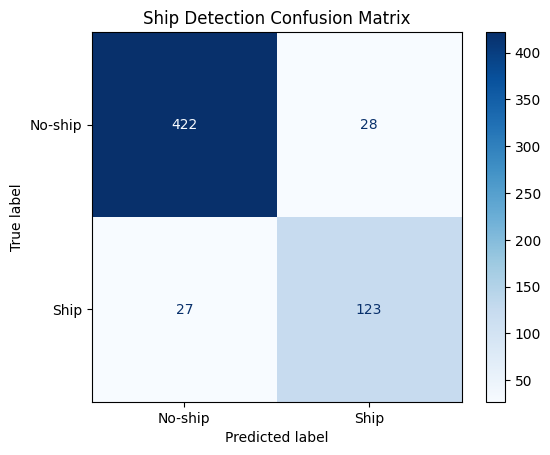

In [18]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# Predict probabilities for the test images
y_prob = model.predict(X_test).ravel()

# Use 0.5 as the initial classification threshold
y_pred = (y_prob >= 0.5).astype(int)

# Calculate accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {test_accuracy:.4f}")

# Per-class precision, recall, F1-score
print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["No-ship", "Ship"],
    digits=4,
    zero_division=0
))

# Macro F1
macro_f1 = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1-score: {macro_f1:.4f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No-ship", "Ship"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Ship Detection Confusion Matrix")
plt.show()

Total misclassified images: 55


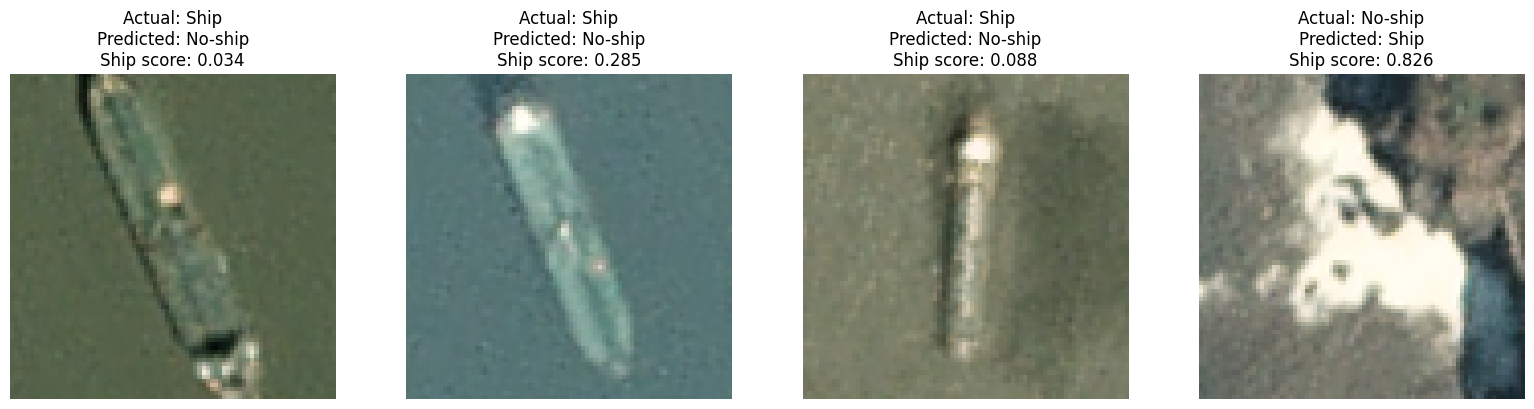

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Find incorrectly classified test images
misclassified_indices = np.where(y_test != y_pred)[0]

print("Total misclassified images:", len(misclassified_indices))

if len(misclassified_indices) == 0:
    print("No misclassified images found in the test set.")
else:
    # Display up to four misclassified images
    n_images = min(4, len(misclassified_indices))

    fig, axes = plt.subplots(1, n_images, figsize=(16, 4))

    if n_images == 1:
        axes = [axes]

    for i, idx in enumerate(misclassified_indices[:n_images]):
        axes[i].imshow(X_test[idx])

        actual = "Ship" if y_test[idx] == 1 else "No-ship"
        predicted = "Ship" if y_pred[idx] == 1 else "No-ship"

        axes[i].set_title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Ship score: {y_prob[idx]:.3f}"
        )

        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

In [20]:
# False negatives: actual ship predicted as no-ship
false_negatives = np.where((y_test == 1) & (y_pred == 0))[0]

# False positives: actual no-ship predicted as ship
false_positives = np.where((y_test == 0) & (y_pred == 1))[0]

print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))

print("\nError analysis:")
print("False negatives may occur when ships are small,")
print("partially visible, blurred, or difficult to distinguish.")

print("\nFalse positives may occur when water patterns,")
print("coastal objects, or other structures resemble ships.")

False negatives: 27
False positives: 28

Error analysis:
False negatives may occur when ships are small,
partially visible, blurred, or difficult to distinguish.

False positives may occur when water patterns,
coastal objects, or other structures resemble ships.


In [21]:
from google.colab import drive
import os

drive.mount("/content/drive")

model_path = (
    "/content/drive/MyDrive/"
    "RA2311026050022_PS28_ship_model.keras"
)

model.save(model_path)

print("Model saved successfully!")
print("Saved at:", model_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!
Saved at: /content/drive/MyDrive/RA2311026050022_PS28_ship_model.keras


In [22]:
import pandas as pd

results_df = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred,
    "Ship_Probability": y_prob,
    "Correct_Prediction": (y_test == y_pred)
})

results_path = (
    "/content/drive/MyDrive/"
    "RA2311026050022_PS28_predictions.csv"
)

results_df.to_csv(results_path, index=False)

print("Predictions saved to:", results_path)
print(results_df.head())

Predictions saved to: /content/drive/MyDrive/RA2311026050022_PS28_predictions.csv
   Actual_Label  Predicted_Label  Ship_Probability  Correct_Prediction
0             0                0          0.000002                True
1             0                0          0.001015                True
2             1                1          0.973330                True
3             0                0          0.004772                True
4             1                0          0.033502               False


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Overall accuracy
accuracy = accuracy_score(y_test, y_pred)

# Metrics for the ship class (label 1)
ship_precision = precision_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

ship_recall = recall_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

ship_f1 = f1_score(
    y_test, y_pred, pos_label=1, zero_division=0
)

# Macro F1
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("FINAL TEST RESULTS")
print("-" * 35)
print(f"Test Accuracy : {accuracy:.4f}")
print(f"Ship Precision: {ship_precision:.4f}")
print(f"Ship Recall   : {ship_recall:.4f}")
print(f"Ship F1-score : {ship_f1:.4f}")
print(f"Macro F1-score: {macro_f1:.4f}")
print(f"Misclassified : {np.sum(y_test != y_pred)}")

FINAL TEST RESULTS
-----------------------------------
Test Accuracy : 0.9083
Ship Precision: 0.8146
Ship Recall   : 0.8200
Ship F1-score : 0.8173
Macro F1-score: 0.8780
Misclassified : 55


In [24]:
from google.colab import drive
import os

drive.mount("/content/drive")

output_dir = "/content/drive/MyDrive/PS28_Ship_Detection"
os.makedirs(output_dir, exist_ok=True)

model.save(os.path.join(output_dir, "ship_detection_model.keras"))

print("Model saved successfully!")
print("Location:", output_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!
Location: /content/drive/MyDrive/PS28_Ship_Detection


In [25]:
import pandas as pd
import os

results = pd.DataFrame({
    "Actual_Label": y_test,
    "Predicted_Label": y_pred,
    "Ship_Probability": y_prob,
    "Correct": y_test == y_pred
})

results_path = os.path.join(
    output_dir,
    "test_predictions.csv"
)

results.to_csv(results_path, index=False)

print("Test predictions saved to:", results_path)

Test predictions saved to: /content/drive/MyDrive/PS28_Ship_Detection/test_predictions.csv
